In [1]:
# Setup: install the checker and download public tests if needed (run first)
%pip install -q otter-grader==7.0.0

import os
import urllib.request

TESTS_URL = "https://raw.githubusercontent.com/NaiveNeuron/ml_exercises/master/assignment4/tests/"
os.makedirs("tests", exist_ok=True)
for name in ["q1_bag_of_words", "q2_cv_models", "q3_tfidf"]:
    path = os.path.join("tests", name + ".py")
    if not os.path.exists(path):
        urllib.request.urlretrieve(TESTS_URL + name + ".py", path)

import otter
grader = otter.Notebook()

Note: you may need to restart the kernel to use updated packages.


# Assignment 4: SVMs, Random Forests, and Text

In this assignment, you will explore SVM decision boundaries and use SVMs and random forests to classify song lyrics. You will build a small bag-of-words representation, then use scikit-learn to compare text classifiers.

### Grading and submission

The assignment is worth up to **12 points**. Exercises 1–8 are worth **7 points** in total. The optional challenges are worth up to **5 additional points**. Complete the exercises in order and write your explanations in the Markdown cells. You can receive partial credit for incomplete work.

Some code exercises have a public `grader.check(...)` cell. These checks cover basic requirements, so passing them does not guarantee full credit. We will also read your explanations and optional work. Save and submit the completed notebook according to your course instructions.

Run the cells in order. You will need NumPy, pandas, matplotlib, scikit-learn and Otter. The notebook runs on a CPU, but cross-validation with the random forest may take a little time.

In [2]:
import os
import re
import urllib.request

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, LinearSVC

DATA_URL = "https://raw.githubusercontent.com/NaiveNeuron/ml_exercises/master/assignment4/"
for name in ["sample_data.csv", "sample_data2.csv", "train_lyrics_1000.csv", "valid_lyrics_200.csv"]:
    if not os.path.exists(name):
        urllib.request.urlretrieve(DATA_URL + name, name)


def plot_boundary(model, X, y, title):
    """Plot a fitted classifier's predictions and the original points."""
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
    predictions = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(5, 4))
    plt.contourf(xx, yy, predictions, alpha=0.25, cmap=plt.cm.coolwarm)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolor="k")
    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

## Part I: SVM decision boundaries

A linear SVM finds a decision boundary by balancing a wide margin against violations of that margin. A larger `C` penalizes violations more strongly. It does not guarantee that all training points will be classified correctly.

We will use a small dataset with two features per point, so we can plot the boundary. The dataset includes a few outliers.

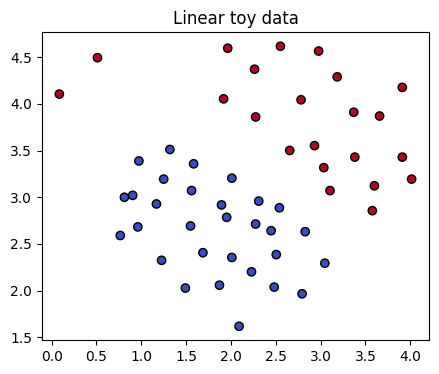

In [3]:
linear_data = np.loadtxt("sample_data.csv", delimiter=",")
X_linear, y_linear = linear_data[:, :2], linear_data[:, 2]
plt.figure(figsize=(5, 4))
plt.scatter(X_linear[:, 0], X_linear[:, 1], c=y_linear, cmap=plt.cm.coolwarm, edgecolor="k")
plt.title("Linear toy data")
plt.show()

<h5 style="color: #1B1BFF">Exercise 1 (1 point)</h5>

Fit linear SVMs with `C = 0.01`, `1` and `100`. Plot each decision boundary with `plot_boundary` and compare how it changes around the outliers. Would a larger `C` always be better for new data? Explain your answer below.

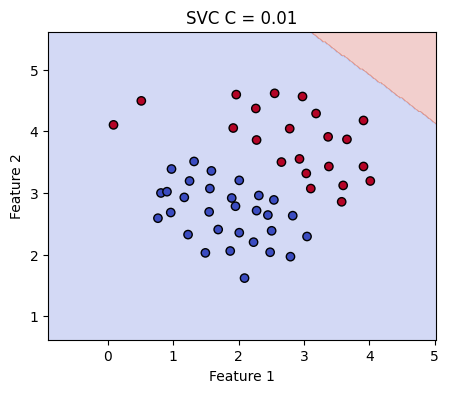

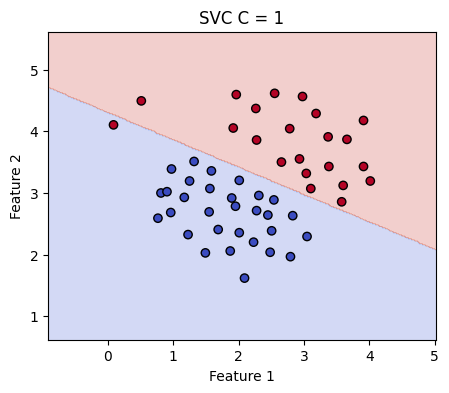

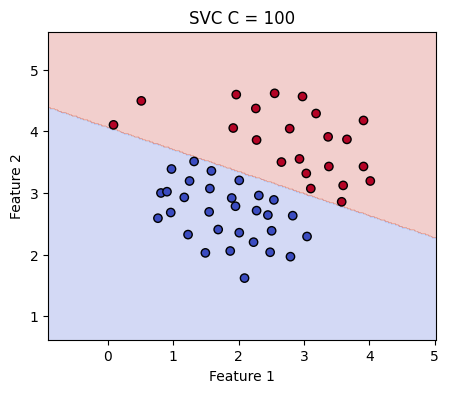

In [4]:
for C in [0.01, 1, 100]:
    svm = SVC(C=C, kernel="linear").fit(X_linear, y_linear)
    plot_boundary(svm, X_linear, y_linear, f"SVC C = {C}")

**Your answer:** 
Pre C = 0.01 model neklasifikuje spravne ani jeden cerveny bod (underfitting).
C = 1 je zlaty stred, kde model okrem jedneho outliera klasifikuje vsetky body spravne.
C = 100 klasifikuje vsetky body spravne, ale vidime ze model "overfituje", lebo sa snazi spravne klasifikovat
aj ten jeden outlier. Z toho vidno ze vacsie C nie je lepsie pre nove data, boundary pre C=1 je viac "vseobecnejsia" a lepsie zodpoveda moznym buducim bodom.


A linear boundary cannot capture every pattern. The RBF (Gaussian) kernel lets an SVM learn nonlinear boundaries. Its `gamma` parameter controls how quickly similarity decreases with distance. A larger `gamma` makes each point's influence more local. The default in `SVC` is `gamma="scale"`. We will set it explicitly.

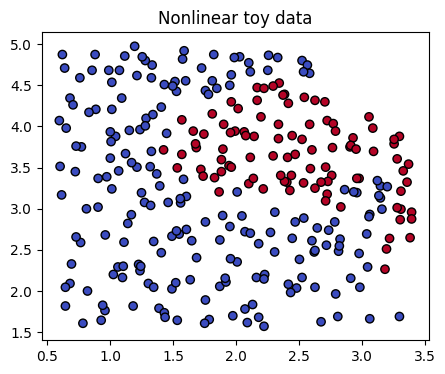

In [5]:
rbf_data = np.loadtxt("sample_data2.csv", delimiter=",")
X_rbf, y_rbf = rbf_data[:, :2], rbf_data[:, 2]
plt.figure(figsize=(5, 4))
plt.scatter(X_rbf[:, 0], X_rbf[:, 1], c=y_rbf, cmap=plt.cm.coolwarm, edgecolor="k")
plt.title("Nonlinear toy data")
plt.show()

<h5 style="color: #1B1BFF">Exercise 2 (1 point)</h5>

Fit and plot RBF SVMs with `C=1` and at least two values of `gamma`, such as `0.01` and `10`. Compare the boundaries and explain what might happen if a boundary follows the training points too closely.

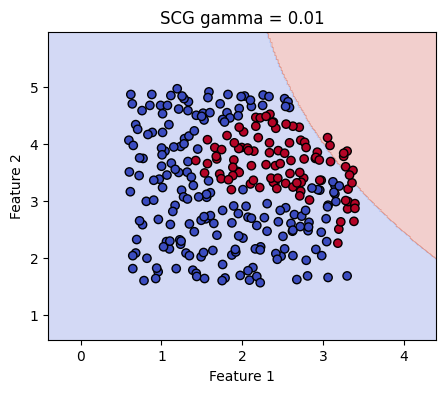

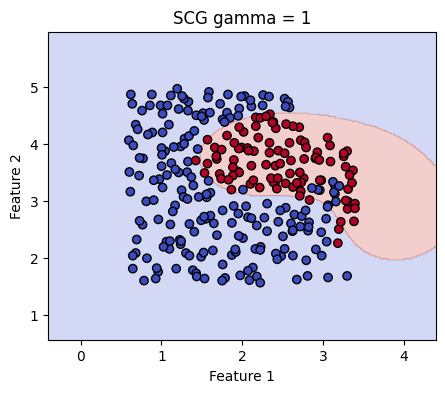

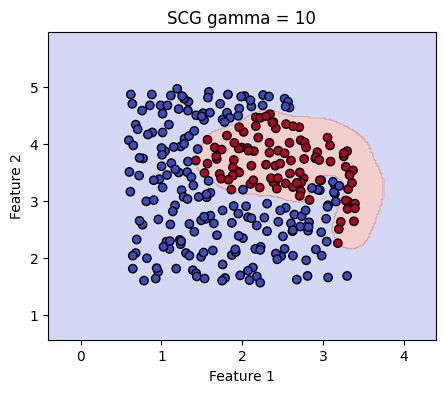

In [6]:
for gamma in [0.01, 1, 10]:
    svm = SVC(C=1, kernel="rbf", gamma=gamma).fit(X_rbf, y_rbf)
    plot_boundary(svm, X_rbf, y_rbf, f"SCG gamma = {gamma}")

**Your answer:**
Pre gamma=0.01 ma kazdy bod  vplyv aj na body, ktore su od neho daleko, preto boundary nevie "oddelit" tie vnutorne cervene body, lebo okolite modre body maju na ne vplyv a kedze ich je viac, model tu vnutornu cast klasifikuje ako modru. 
Pre gamma = 10 je ten vplyv viac lokalny, teda boundary uz vie oddelit vnutorne cervene body.
Cim viac boundary nasleduje treningove body, tym viac sa model overfituje na treningovych datach. 

## Part II: From words to numbers

Next, we will use song lyrics to predict whether a song is labeled `happy` or `sad`. These labels simplify the task: a song can express mixed emotions, and people may disagree about its label. The model needs numerical features, though scikit-learn can work with string labels.

A **bag of words** represents each text by the counts of words in a fixed vocabulary. For the vocabulary `["happy", "not", "sad"]`, the tokens `["not", "sad", "sad"]` become `[0, 1, 2]`. The representation keeps the counts but loses the word order.

<h5 style="color: #1B1BFF">Exercise 3 (1 point)</h5>

Implement `count_words(tokens, vocabulary)`. Return a one-dimensional NumPy array with one count for each word, in vocabulary order. Ignore tokens that are not in the vocabulary. You can assume the vocabulary has no duplicates and the text is already tokenized. Do not use scikit-learn in this exercise.

In [7]:
def count_words(tokens, vocabulary):
    # could be done easier with defaultdict
    count = {}
    for word in vocabulary:
        count[word] = 0
    for token in tokens:
        if token not in vocabulary:
            continue
        count[token] += 1
    return np.array(list(count.values()))

vocabulary = ["happy", "not", "sad"]
print(count_words(["not", "sad", "sad"], vocabulary))  # [0, 1, 2]

[0 1 2]


In [8]:
grader.check("q1_bag_of_words")

q1_bag_of_words results: All test cases passed!

### An explicit pipeline

The cell below shows each step of a small text-classification pipeline. We tokenize the training texts, build a vocabulary from them, and count words in both the training and new texts using that vocabulary. Words outside the vocabulary are ignored.

Each row of the resulting NumPy arrays represents a text, and each column represents a word. These dense arrays are useful for a small example. Real vocabularies can be large, so scikit-learn uses sparse matrices that store the nonzero counts instead.

In [9]:
def tokenize(text):
    return re.findall(r"[a-z]+", text.lower())

small_train = ["Happy day", "Not a happy day", "Sad night"]
small_new = ["Not sad tonight"]
train_tokens = [tokenize(text) for text in small_train]
new_tokens = [tokenize(text) for text in small_new]
training_vocabulary = sorted({word for tokens in train_tokens for word in tokens})

train_counts = np.array([count_words(tokens, training_vocabulary) for tokens in train_tokens])
new_counts = np.array([count_words(tokens, training_vocabulary) for tokens in new_tokens])
print("Vocabulary:", training_vocabulary)
print("Training counts:\n", train_counts)
print("New-text counts:\n", new_counts)

# Complete the toy workflow by fitting and predicting with the count matrices.
# The tiny data is only for demonstration, not for evaluating a model.
small_labels = ["happy", "happy", "sad"]
toy_classifier = LinearSVC(random_state=42)
toy_classifier.fit(train_counts, small_labels)
print("Prediction for new text:", toy_classifier.predict(new_counts))

Vocabulary: ['a', 'day', 'happy', 'night', 'not', 'sad']
Training counts:
 [[0 1 1 0 0 0]
 [1 1 1 0 1 0]
 [0 0 0 1 0 1]]
New-text counts:
 [[0 0 0 0 1 1]]
Prediction for new text: ['sad']


<h5 style="color: #1B1BFF">Exercise 4 (0.5 points)</h5>

Explain why we use the training vocabulary to transform `small_new` and what happens to the word `tonight`. Why could building the vocabulary from all texts before splitting them make the evaluation less trustworthy?

**Your answer:**
Lebo nas model bol natrenovany prave na training_vocabulary a kedze slovo "tonight" sa v nom nenachadza, nema pren "naucene vahy" a nema ho pre klasifikaciu ani ako pouzit a tak vypadne.

Ak by sme sa pozreli ake slova mame v testovacom datasete a nasledne podla toho vytvorili slovnik, tak by sme modelu "leakli" informacie z testovania a vysledky by boli menej doveryhodne, lebo by nereprezentovali skutocnu schopnost klasifikovat uplne nove texty. Toto sa oznacuje ako data leakage.

## Part III: Classifying lyrics

We have 1,000 labeled training songs and a separate file with 200 held-out songs. We will compare models using five-fold cross-validation on the training songs, then evaluate the chosen model once on the held-out songs.

Five held-out rows have lyrics that also appear in the training set. The next cell removes held-out rows with lyrics identical to a training row. It does not change the CSV files. The files still share some artists, so the final score does not tell us how well the model works on new artists.

The training set also contains eight pairs of identical lyrics, including two pairs with conflicting labels. A pair can end up on both sides of a cross-validation split, which can make the score too optimistic. We keep these rows and consider this when interpreting the results. We do not use the supplied vocabulary file because its origin is undocumented.

In [10]:
df_train = pd.read_csv("train_lyrics_1000.csv")
df_heldout = pd.read_csv("valid_lyrics_200.csv")

# Filter only exact lyric overlaps; no held-out labels are used here.
overlap = df_heldout["lyrics"].isin(df_train["lyrics"])
print("Held-out rows removed due to exact lyric overlap:", int(overlap.sum()))
df_heldout = df_heldout.loc[~overlap].reset_index(drop=True)

X_train, y_train = df_train["lyrics"], df_train["mood"]
X_heldout, y_heldout = df_heldout["lyrics"], df_heldout["mood"]
print("Training songs:", len(X_train), "| held-out songs:", len(X_heldout))
print("Training label counts:")
print(y_train.value_counts())

Held-out rows removed due to exact lyric overlap: 5
Training songs: 1000 | held-out songs: 195
Training label counts:
mood
sad      554
happy    446
Name: count, dtype: int64


### Cross-validation with a pipeline

A majority-class baseline always predicts the most common label in its training data. It gives us a simple result to compare with the other models.

`CountVectorizer` learns a vocabulary and returns a sparse matrix of word counts. A scikit-learn `Pipeline` combines the vectorizer and the classifier. During cross-validation, it fits the vectorizer separately on the training portion of each fold. If we built the vocabulary before cross-validation, words from the validation portions would influence it.

For five-fold cross-validation, we split the training data into five parts. We train on four parts and score on the fifth, repeating this until each part has been used for scoring. We use the same stratified folds for each model. This keeps class proportions similar across folds. The fixed random seed makes the split reproducible. Songs by the same artist can still appear on both sides of a split.

In [11]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "baseline": DummyClassifier(strategy="most_frequent"),
    "svm": make_pipeline(CountVectorizer(), LinearSVC(C=0.1, max_iter=20000, random_state=42)),
    "forest": make_pipeline(CountVectorizer(), RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)),
}

<h5 style="color: #1B1BFF">Exercise 5 (1 point)</h5>

Use `cross_val_score` to evaluate each model in `models` on `X_train` and `y_train`. Use `folds` and accuracy as the metric. Store each model's five scores in the `cv_results` dictionary under its name, then print the mean score for each model. Do not fit the vectorizer before cross-validation.

In [12]:
cv_results = {}
for name, model in models.items():
    acc = cross_val_score(model, X_train, y_train, cv=folds, scoring="accuracy")
    # print(acc)
    cv_results[name] = acc
    

for name, scores in cv_results.items():
    print(f"{name}: {np.mean(scores):.3f} (folds: {np.round(scores, 3)})")

baseline: 0.554 (folds: [0.555 0.555 0.555 0.555 0.55 ])
svm: 0.607 (folds: [0.605 0.575 0.6   0.605 0.65 ])
forest: 0.659 (folds: [0.63  0.7   0.695 0.65  0.62 ])


In [13]:
grader.check("q2_cv_models")

q2_cv_models results: All test cases passed!

<h5 style="color: #1B1BFF">Exercise 6 (0.5 points)</h5>

Compare the models with the baseline. Describe how much the scores vary across folds and what the results suggest. Why might the models perform differently on other songs?

**Your answer:**
SVM aj Forest oba prekonavaju baseline (0.55, co je podiel vacsinoveho labelu, sad). Forest (0.659) je o nieco lepsi ako SVM (0.607). 
Pri oboch modeloch vidime rozptyl cez foldy priblizne 0.08, co znamena, ze zalezi na ktorom folde sa model trenoval/testoval. To sa da ocakavat, kedze mame pomerne maly testovaci set.
Dovody preco model moze mat iny vysledok na inych piesnach mozu byt mala velkost dat, spominane problemy so subjektivitou labelov a duplicitne texty v datach (ak jeden z paru je v treningovom set a druhy je v testovacom, tak model sa doslova "nauci" text a jeho spravny label).

### Does the representation matter?

Raw counts are one way to represent words. Term frequency–inverse document frequency (TF–IDF) gives less weight to words that are common across the training documents. We will compare the two representations using the same linear SVM and folds.

In [14]:
tfidf_svm = make_pipeline(
    TfidfVectorizer(),
    LinearSVC(C=0.1, max_iter=20000, random_state=42),
)

<h5 style="color: #1B1BFF">Exercise 7 (1 point)</h5>

Use `cross_val_score` to evaluate `tfidf_svm` on the same training data and folds, using accuracy as the metric. Store the five scores in `tfidf_scores` and compare their mean with `cv_results["svm"]`. Which representation would you choose, and why might the result differ with another split?

In [15]:
tfidf_scores = cross_val_score(tfidf_svm, X_train, y_train, cv=folds, scoring="accuracy")
print(tfidf_scores)
print("TF–IDF + SVM:", np.mean(tfidf_scores))
print("Counts + SVM:", np.mean(cv_results["svm"]))

[0.635 0.66  0.595 0.68  0.66 ]
TF–IDF + SVM: 0.646
Counts + SVM: 0.607


In [16]:
grader.check("q3_tfidf")

q3_tfidf results: All test cases passed!

**Your answer:** 
Kedze TF-IDF + SVM ma lepsi priemer (0.646) ako Counts + SVM (0.607), vybral by som to. 
Ak by sme pouzili iny split, tak mozeme ocakavat ine vysledky a to preto, lebo by sa do testovacieho setu dostali ine pesnicky.
Vzhladom na obmedzenu velkost datasetu, aj mala zmena v tom, ktore piesne sa dostanu do testovacieho setu, vedia zmenit vysledok. 

### Final evaluation

Choose one of the four approaches using the training cross-validation results. If you want to consider a bonus approach too, run that comparison before choosing your model. Fit it on all training lyrics and evaluate it once on the held-out set. If you use the held-out score to choose or change your model, it no longer gives an independent final assessment.

Held-out accuracy: 0.6153846153846154


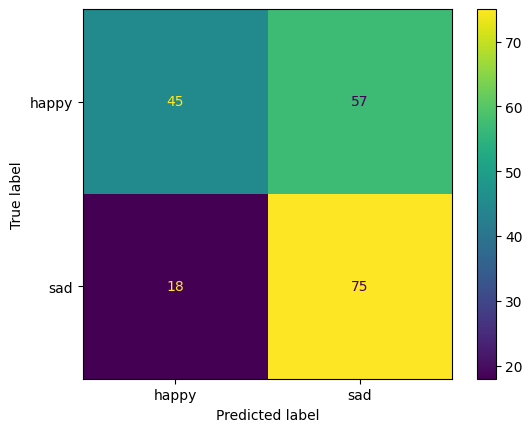

In [17]:
candidates = {**models, "tfidf_svm": tfidf_svm}
# Set chosen_name to one of: "baseline", "svm", "forest", "tfidf_svm".
chosen_name = "forest"
chosen_model = candidates[chosen_name]
chosen_model.fit(X_train, y_train)
heldout_predictions = chosen_model.predict(X_heldout)
print("Held-out accuracy:", accuracy_score(y_heldout, heldout_predictions))
ConfusionMatrixDisplay.from_predictions(y_heldout, heldout_predictions)
plt.show()

<h5 style="color: #1B1BFF">Exercise 8 (1 point)</h5>

Explain your model choice using the cross-validation results. How does its held-out score compare with those results and the baseline cross-validation score? The scores come from different samples, so interpret the comparison with care.

Use the cell below to inspect two incorrect predictions. What might explain the errors? Discuss at least one limitation of the dataset or split. Remember that a song can express more than one emotion and that word order can change meaning.

In [18]:
errors = df_heldout.loc[heldout_predictions != y_heldout.to_numpy(), ["artist", "title", "lyrics", "mood"]].copy()
errors["prediction"] = heldout_predictions[heldout_predictions != y_heldout.to_numpy()]
for _, row in errors.head(2).iterrows():
    print(f"{row['artist']} — {row['title']} | label: {row['mood']} | prediction: {row['prediction']}")
    print(row["lyrics"][:500], "\n")

Placebo — Where Is My Mind (XFM Live Version) | label: happy | prediction: sad
Ooooohh
Ooooohh
Ooooohh
Ooooohh

With your feet on the air and your head on the ground
You try this trick and spin it
Yeah (yeah)
Your head will collapse
And there's nothing in it
And you'll ask yourself

Where is my mind
Where is my mind
Where is my mind
Where is my mind

Way out 
In the water, see her swimming

I was swimming in the Caribbean
The animals would hide behind the rocks
Except the little fish
When they told me east is west
As they tried to cry

Where is my mind
Where is my mind
Whe 

Wilshire — Special | label: happy | prediction: sad
I ride in on the train
Everyday is the same old thing
It's 9 to 5
Don't know if I'm dead already

I'm lookin' for a hallelujah
I need a little something special
(Something special)

My walls are gray
Makes me feel like I live in a cave
I'm wearing fear
And when tomorrow comes I'll do it all again again again

I'm looking for a hallelujah
I need a little something 

**Your answer:** 
Model "forest" som vybral preto, lebo mal najvyssi cross-validation priemer spomedzi vsetkych modelov.
Held-out skore je nizsie (0.615) ako CV priemer (0.659), co sa da vysvetlit tym, ze held-out set je mensi a moze byt "narocnejsie" zlozeny nez trenovacie foldy. Taktiez CV skore je spriemerovane cez 5 merani, kde held-out skore je iba z jedneho merania, takze ten rozptyl moze byt vacsi.
Co sa tyka tych dvoch zlych predikcii, tak vysvetlenie preco model predikoval label "sad", aj ked spravny je "happy", je pritomnost slov "cry", "gray", "fear" a "dead" v texte.
Limitacia tohto datasetu je jej velkost, teda par chyb velmi hybe so skore, klasifikacia piesni vie byt v niektorych pripadoch velmi subjektivna a taktiez je kategorizacia na  "happy" alebo "sad" velmi zjednodusujuca.

## Optional challenges: up to 5 bonus points

The challenges below offer up to 7 points, but you can receive at most **5 bonus points**. Together with the 7 required points, the maximum for the assignment is **12 points**. Choose the challenges you find interesting and add your code, results and explanations in new cells below.

Use the training data and the same cross-validation folds for your comparisons. Do not use the held-out set to tune your models. You do not need to improve accuracy to get full credit. A careful comparison and explanation are enough. The majority baseline and TF–IDF comparison are already required, so they do not earn bonus points on their own.

### 1. A different baseline (up to 1 point)

Design another simple baseline, such as a classifier that predicts from a small, fixed list of sentiment words. Compare it with the majority-class baseline using the same training folds. Explain how it works and what the comparison tells you. You can earn up to 0.5 points for a reproducible comparison and 0.5 points for the explanation.

### 2. Test another preprocessing choice (up to 1 point)

Compare the count-based linear SVM with and without a preprocessing step, such as stop-word removal or stemming. Keep the training data, model settings and folds the same. Report both mean cross-validation scores. What information might the preprocessing step remove? Give an example if you can. The comparison is worth up to 0.5 points, and the explanation is worth another 0.5 points.

### 3. Try metadata (up to 2 points)

Try adding `title` or `genre` to the lyrics-based model. Use the same training data and folds, and fit any learned transformations inside the cross-validation pipeline. You can use `ColumnTransformer` to combine text and metadata. Pass the needed columns from `df_train` to cross-validation instead of the lyrics-only `X_train`. Compare the result with a lyrics-only model and discuss a limitation of using metadata. Both fields are available in the supplied files, but the held-out file has no `year` column. You can earn up to 1 point for the implementation and comparison, and 1 point for the explanation.

### 4. Do something cool (up to 3 points)

Try another idea using the provided data and models from this assignment. For example, compare several hyperparameter settings, inspect multiple shallow trees in a random forest, or try another text representation. Describe what you tried, report cross-validation results where applicable, and explain what you found and what the limitations are. You can earn up to 1 point for the question and approach, 1 for the implementation and evidence, and 1 for the explanation. You cannot receive points twice for the same work.

In [19]:
# 1. different baseline
happy_words = ["happy", "love", "sun", "sunny", "smile", "smiling", "joy", "laugh", "laughing", "dance", "dancing", "kiss", "fun"]
sad_words = ["sad", "sadness", "pain", "cry" , "crying", "tears", "painful", "hurt", "lonely", "death", "darkness", "regret", "grief"]

def predict_sentiment(text):
    tokens = tokenize(text)
    happy_count, sad_count = 0, 0
    for token in tokens:
        if token in happy_words:
            happy_count += 1
        elif token in sad_words:
            sad_count += 1
    
    if happy_count > sad_count:
        return "happy"
    elif sad_count > happy_count:
        return "sad"
    else:
        return "sad"  # sad lebo je majority 

scores = []
for train_fold, test_fold in folds.split(X_train, y_train):
    X_test_fold = X_train.iloc[test_fold]
    y_test_fold = y_train.iloc[test_fold]
    predictions = []
    for text in X_test_fold:
        predictions.append(predict_sentiment(text))
    scores.append(accuracy_score(y_test_fold, predictions))

scores = np.array(scores)
print("Sentiment baseline:", np.round(scores, 3), scores.mean())
print("Majority class baseline:", np.round(cv_results["baseline"], 3), np.mean(cv_results["baseline"]))


Sentiment baseline: [0.56  0.575 0.59  0.6   0.615] 0.5880000000000001
Majority class baseline: [0.555 0.555 0.555 0.555 0.55 ] 0.554


Pre kazdu piesen spocita kolko slov sa nachadza v happy alebo sad zozname a klasifikuje ju podla toho, ktorych slov je viac. Ak sa pocet slov rovna, vratime "sad", lebo je to vacsinovy label.
Ak to porovname s povodnym baselinom (0.554), tak nas pristup je o nieco lepsi (0.588).

In [20]:
# 2. another preprocessing choice 
stop_words_svm = make_pipeline(
    CountVectorizer(stop_words="english"),
    LinearSVC(C=0.1, max_iter=20000, random_state=42),
)

stopword_scores = cross_val_score(stop_words_svm, X_train, y_train, cv=folds, scoring="accuracy")
print("Counts + stop-words + SVM:", np.round(stopword_scores, 3), stopword_scores.mean())
print("Counts + SVM:", np.round(cv_results["svm"], 3), np.mean(cv_results["svm"]))

Counts + stop-words + SVM: [0.68  0.655 0.645 0.63  0.61 ] 0.6439999999999999
Counts + SVM: [0.605 0.575 0.6   0.605 0.65 ] 0.607


Stop word preprocessing odstrani slova/tokeny, ktore nepridavaju klasifikacii ziaden vyznam, napr: "the", "a", "an", "is", "and", ...
Napriklad z vety: "From the sky and towards the ground" zostanu iba tokeny: "sky", "ground".
Tento preprocessing moze odstanit informaciu o negacii nejakeho slova, co by znamenalo ze zmeni vyznam, napr.: "not happy" -> "happy".
Ale v nasom pripade je to aj tak jedno, lebo zo spojenia "not happy", by Tokenizer aj tak vytvoril ["not", "happy"], takze model by aj tak videl slovo "happy" 
bez negacie.

Pridanie stop word preprocessingu (0.644) dava lepsie vysledky ako obycajny Counts + SVM baseline.

In [21]:
# 3. metadata
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

X_meta = df_train[["lyrics", "genre"]]

preprocess = ColumnTransformer([
    ("text", CountVectorizer(), "lyrics"),
    ("genre", OneHotEncoder(handle_unknown="ignore"), ["genre"]),
])

metadata_svm = make_pipeline(preprocess, LinearSVC(C=0.1, max_iter=20000, random_state=42))
metadata_scores = cross_val_score(metadata_svm, X_meta, y_train, cv=folds, scoring="accuracy")

print("Lyrics + Genre + SVM:", np.round(metadata_scores, 3), metadata_scores.mean())
print("Lyrics + SVM:", np.round(cv_results["svm"], 3), np.mean(cv_results["svm"]))

Lyrics + Genre + SVM: [0.605 0.585 0.58  0.59  0.665] 0.605
Lyrics + SVM: [0.605 0.575 0.6   0.605 0.65 ] 0.607


Pridanie zanru k textu piesne prakticky nezmenilo presnost, priemer je skoro rovnaky ako priemer modelu, ktory pouziva iba text piesni. To znamena, ze zaner nepridava
informacie nad to, co uz pridava text piesne.

In [22]:
# 4. do something cool - n_estimators on RandomForest
n_estimators = [1, 5, 10, 50, 100, 200, 500]
forest_results = {}

for n in n_estimators:
    model = make_pipeline(CountVectorizer(), RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1))
    scores = cross_val_score(model, X_train, y_train, cv=folds, scoring="accuracy")
    forest_results[n] = scores
    print(f"n_estimators={n:d} mean={scores.mean():.3f}")

n_estimators=1 mean=0.551
n_estimators=5 mean=0.563
n_estimators=10 mean=0.598
n_estimators=50 mean=0.659
n_estimators=100 mean=0.662
n_estimators=200 mean=0.660
n_estimators=500 mean=0.655


Na vysledkoch si mozeme vsimnut ze presnost rastla od 1 do 50 stromov (0.551 -> 0.659) a nasledne medzi hodnotami 100, 200 a 500 je rozdiel v priemere zanedbatelny (0.662, 0.660, 0.655). Kazdy strom sa uci na inej mnozine dat a robi ine chyby, ale tym ze sa nakoniec spriemeruje, tak sa tieto chyby vyrovnaju. Preto pri velkom pocte stromov sa priemer nezvysi.